# S1 · EDA and realism review

**Goal:** check that the simulated feed behaves like a real automated cold-store's outbound
volume *before* we build anything on it, and record what S2+ must handle.

Sections 1–6 read only **`data/validated/`**, which is what downstream stages will see.
Section 7 compares against `data/sim_truth/` to audit the pipeline; nothing downstream
may read the truth.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
V = ROOT / "data" / "validated"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Reference palette (dataviz skill), categorical slots in fixed order; ink tokens for text.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "font.size": 9, "axes.titlesize": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 1.4, "axes.titlecolor": INK,
    "axes.titlelocation": "left", "figure.facecolor": "white",
})

ship = pd.read_parquet(V / "shipments.parquet")
sites = pd.read_parquet(V / "master" / "sites.parquet")
cust = pd.read_parquet(V / "master" / "customers.parquet")
promo = pd.read_parquet(V / "master" / "promo_calendar.parquet")
hol = pd.read_parquet(V / "master" / "holidays.parquet")
SITE_IDS = sites["site_id"].tolist()
CUTOFF = pd.Timestamp("2026-01-01")

site_day = ship.groupby(["site_id", "ship_date"])["pallets"].sum().rename("pallets").reset_index()
cust_day = (ship.groupby(["site_id", "customer_id", "ship_date"])["pallets"].sum()
            .rename("pallets").reset_index())
print(f"{len(ship):,} shipments | {ship.ship_date.min().date()} → {ship.ship_date.max().date()}")
print(sites.to_string(index=False))

248,729 shipments | 2023-01-02 → 2026-09-30
site_id country  capacity_pallets_per_day              operating_days
    S01      NL                      2400     Mon,Tue,Wed,Thu,Fri,Sat
    S02      GB                      3600 Mon,Tue,Wed,Thu,Fri,Sat,Sun
    S03      DE                      3200     Mon,Tue,Wed,Thu,Fri,Sat
    S04      ES                      2200     Mon,Tue,Wed,Thu,Fri,Sat


## 1. Volume over time (weekly totals per site)
Dashed line = history / live split. Markers = known business events from master data.

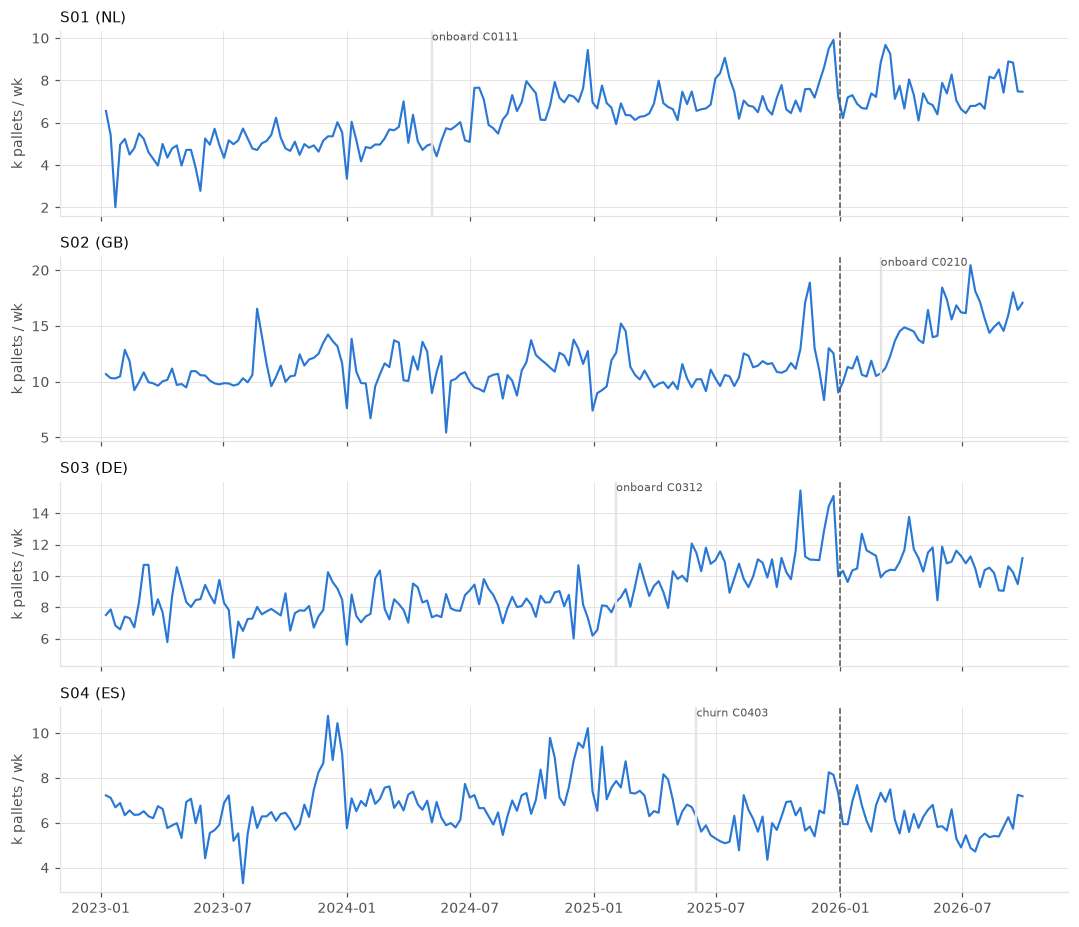

In [2]:
wk = (site_day.set_index("ship_date").groupby("site_id")["pallets"].resample("W-MON").sum()
      .reset_index())
# drop partial first/last weeks so edges are not artificial dips
wk = wk[(wk.ship_date > site_day.ship_date.min() + pd.Timedelta(days=6))
        & (wk.ship_date <= site_day.ship_date.max())]
fig, axes = plt.subplots(4, 1, figsize=(10, 8.5), sharex=True)
for ax, s in zip(axes, SITE_IDS):
    g = wk[wk.site_id == s]
    ax.plot(g.ship_date, g.pallets / 1000, color=SERIES[0])
    ax.axvline(CUTOFF, color=INK2, ls="--", lw=1)
    for c in cust[(cust.site_id == s) & cust.onboard_date.notna()].itertuples():
        ax.annotate(f"onboard {c.customer_id}", (c.onboard_date, ax.get_ylim()[1]), fontsize=7,
                    color=INK2, va="top")
        ax.axvline(c.onboard_date, color=GRID, lw=1.5)
    for c in cust[(cust.site_id == s) & cust.churn_date.notna()].itertuples():
        ax.annotate(f"churn {c.customer_id}", (c.churn_date, ax.get_ylim()[1]), fontsize=7,
                    color=INK2, va="top")
        ax.axvline(c.churn_date, color=GRID, lw=1.5)
    ax.set_title(f"{s} ({sites.set_index('site_id').country[s]})")
    ax.set_ylabel("k pallets / wk")
fig.tight_layout(); fig.savefig(FIG / "s1_weekly_volume.png")

**Read:** steady growth at S01/S03, a pre-Christmas peak at every site (strongest at S04, whose mix is mostly
ready meals and seafood), a post-Christmas lull, and visible steps at onboarding (S01 mid-2024, S03 early 2025)
and churn (S04 mid-2025). Each site's yearly shape is set by its customer mix, so a single global seasonal
curve will not fit. In the live period (2026) S02
jumps (new ice-cream client + Saturday shift) and S04 drops from June. Those are **real business changes** and
validation correctly did *not* flag them. Catching them is S7's job. S04's July–August 2026 volume (~23.3k
pallets/month) is the lowest of the four years (24.7k–30.4k). It's a subtle site-level shift: one large
customer lost about a third of its volume, master data doesn't record it, and it's hard to see by eye.
That makes it a deliberate test for S7, which has to catch it from the data alone.

## 2. Day-of-week profile

dow,0,1,2,3,4,5,6
site_id,,,,,,,
S01,1.13,1.00,1.00,1.00,0.94,0.32,NaN
S02,1.08,0.99,0.98,1.03,0.97,0.41,0.12
S03,1.13,1.01,1.00,0.99,0.98,0.28,NaN
S04,1.06,1.01,0.99,1.00,0.94,0.23,NaN


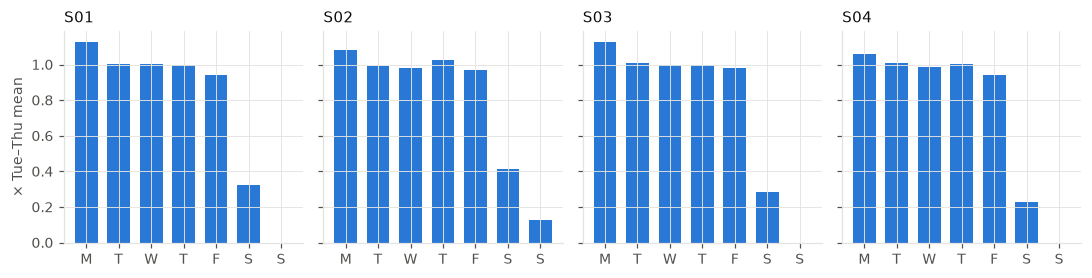

In [3]:
sd = site_day.assign(dow=site_day.ship_date.dt.dayofweek)
hist = sd[sd.ship_date < CUTOFF]
prof = hist.groupby(["site_id", "dow"])["pallets"].mean().unstack()
prof = prof.div(prof.loc[:, 1:3].mean(axis=1), axis=0)  # relative to Tue–Thu
fig, axes = plt.subplots(1, 4, figsize=(10, 2.6), sharey=True)
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
for ax, s in zip(axes, SITE_IDS):
    ax.bar(range(7), prof.reindex(columns=range(7)).loc[s].fillna(0), color=SERIES[0], width=0.7)
    ax.set_xticks(range(7), [d[0] for d in days]); ax.set_title(s)
axes[0].set_ylabel("× Tue–Thu mean")
fig.tight_layout(); fig.savefig(FIG / "s1_weekday.png")
prof.round(2)

Monday catch-up, light Saturdays, Sundays closed except S02 (GB). Weekday is the single strongest signal, so S2 needs weekday features and per-site handling of closed days.

## 3. Annual seasonality by customer segment
Each customer's volume divided by its own yearly mean (removes size and growth), then a 7-day rolling mean by day of year. History only.

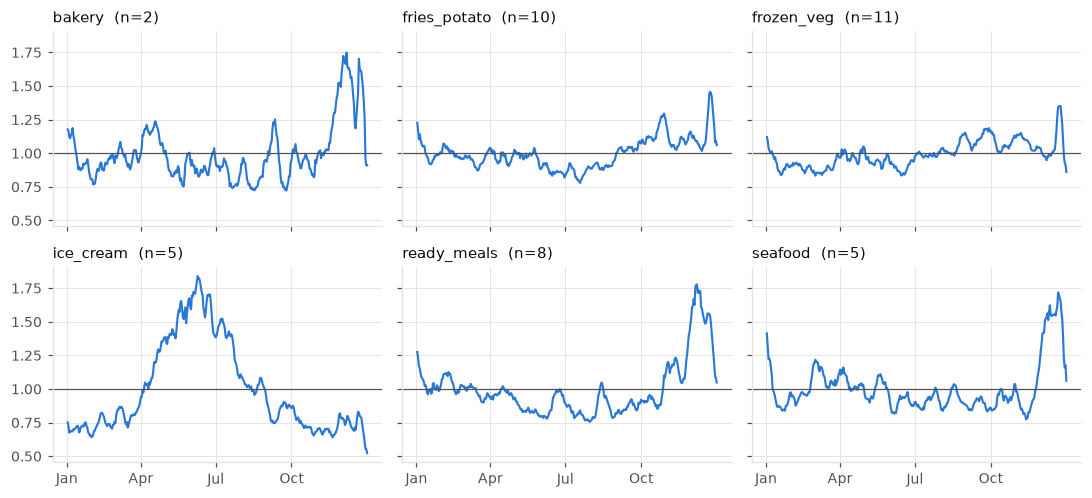

In [4]:
cd = cust_day.merge(cust[["customer_id", "segment"]], on="customer_id")
cd = cd[cd.ship_date < CUTOFF].copy()
cd["year"] = cd.ship_date.dt.year
cd["norm"] = cd.pallets / cd.groupby(["customer_id", "year"]).pallets.transform("mean")
cd["doy"] = cd.ship_date.dt.dayofyear
segs = sorted(cd.segment.unique())
fig, axes = plt.subplots(2, 3, figsize=(10, 4.6), sharey=True, sharex=True)
for ax, sg in zip(axes.flat, segs):
    g = cd[cd.segment == sg].groupby("doy").norm.mean().rolling(7, center=True, min_periods=1).mean()
    ax.plot(g.index, g.values, color=SERIES[0]); ax.axhline(1, color=INK2, lw=0.8)
    ax.set_title(f"{sg}  (n={cd[cd.segment == sg].customer_id.nunique()})")
    ax.set_xticks([1, 91, 182, 274], ["Jan", "Apr", "Jul", "Oct"])
fig.tight_layout(); fig.savefig(FIG / "s1_seasonality.png")

Ice cream peaks in early summer, while bakery, seafood and ready meals peak before Christmas. Seasonality is segment-specific, so S2 should give the model a segment-level seasonal signal rather than one global calendar.

## 4. Autocorrelation of daily site volume

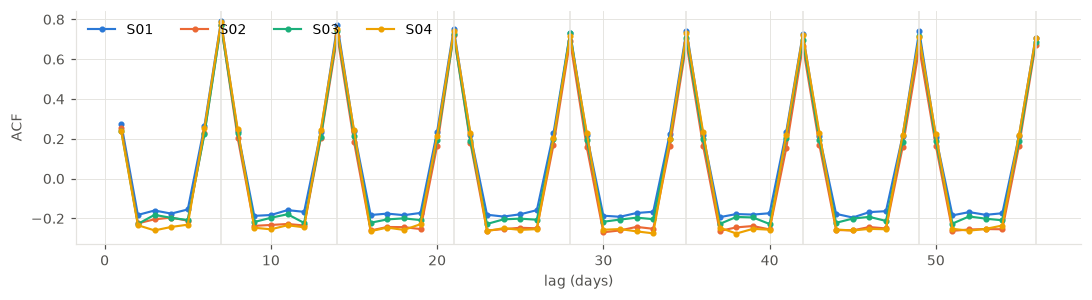

In [5]:
fig, ax = plt.subplots(figsize=(10, 2.8))
for i, s in enumerate(SITE_IDS):
    y = site_day[(site_day.site_id == s) & (site_day.ship_date < CUTOFF)].set_index("ship_date").pallets
    y = y.reindex(pd.date_range(y.index.min(), y.index.max()), fill_value=0)
    ax.plot(range(1, 57), acf(y, nlags=56)[1:], color=SERIES[i], marker="o", ms=3, label=s)
for k in range(7, 57, 7):
    ax.axvline(k, color=GRID, lw=1)
ax.set_xlabel("lag (days)"); ax.set_ylabel("ACF"); ax.legend(ncol=4, frameon=False)
fig.tight_layout(); fig.savefig(FIG / "s1_acf.png")

The ACF is dominated by the weekly cycle (about 0.75 at every multiple of 7, barely decaying over 8 weeks; negative in between because weekends are low). **Lag-7/14/28 and same-weekday rolling means** are the obvious feature set for S2, and seasonal-naive (lag-7) is the baseline any model must beat in S3.

## 5. Holiday effect
Site volume around public holidays that fall on operating days, relative to the same-weekday median of the 8 previous weeks.

k,-5,-4,-3,-2,-1,0,1,2,3,4
median,1.04,1.13,1.13,1.31,1.3,0.0,1.19,1.13,0.98,1.0
count,94.00,93.00,105.00,110.00,87.0,115.0,108.00,94.00,93.00,105.0


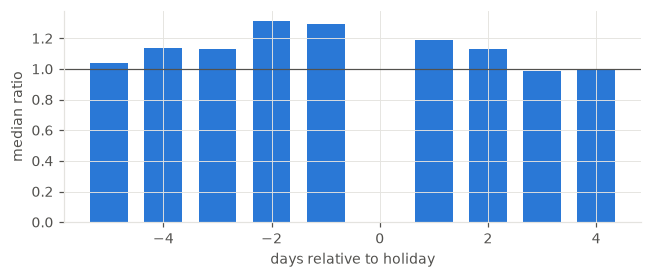

In [6]:
ops = {s.site_id: {days.index(d) for d in s.operating_days.split(",")} for s in sites.itertuples()}
piv = site_day.set_index(["site_id", "ship_date"]).pallets
rows = []
for s in sites.itertuples():
    hd = hol[(hol.country == s.country) & hol.date.dt.dayofweek.isin(ops[s.site_id])
             & (hol.date > ship.ship_date.min() + pd.Timedelta(days=70))
             & (hol.date < ship.ship_date.max())].date
    for h in hd:
        for k in range(-5, 5):
            d = h + pd.Timedelta(days=k)
            if d.dayofweek not in ops[s.site_id]:
                continue
            ref = [piv.get((s.site_id, d - pd.Timedelta(weeks=w)), np.nan) for w in range(1, 9)]
            rows.append({"k": k, "ratio": piv.get((s.site_id, d), 0) / np.nanmedian(ref)})
he = pd.DataFrame(rows).groupby("k").ratio.agg(["median", "count"])
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(he.index, he["median"], color=SERIES[0], width=0.7); ax.axhline(1, color=INK2, lw=0.8)
ax.set_xlabel("days relative to holiday"); ax.set_ylabel("median ratio")
fig.tight_layout(); fig.savefig(FIG / "s1_holiday.png")
he.round(2).T

Volume is zero on the holiday, raised over the 1–3 working days before (pre-build) and slightly raised after (catch-up). S2 needs **days-to-next-holiday and days-since-last-holiday** features, not just an is-holiday flag.

## 6. Promotion effect (event study)
Customer daily volume relative to its 28-day pre-period median, aligned on the **in-store** promo start from the promo calendar.

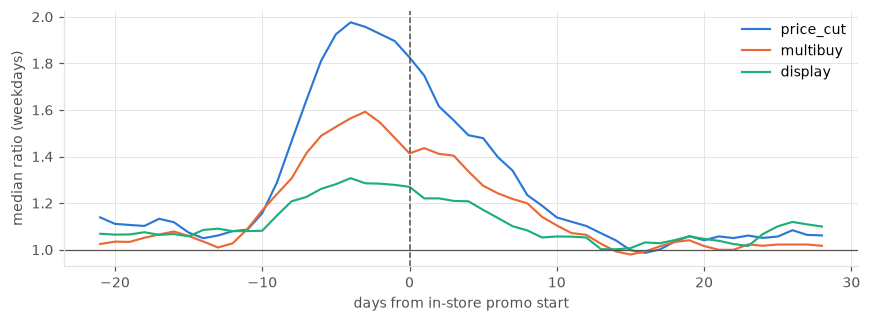

In [7]:
cv = cust_day.set_index(["customer_id", "ship_date"]).pallets
rows = []
for p in promo[(promo.start_date > ship.ship_date.min() + pd.Timedelta(days=60))
               & (promo.end_date < CUTOFF)].itertuples():
    base = [cv.get((p.customer_id, p.start_date - pd.Timedelta(days=d)), np.nan) for d in range(30, 58)]
    b = np.nanmedian(base)
    if not b or np.isnan(b):
        continue
    for k in range(-21, 29):
        d = p.start_date + pd.Timedelta(days=k)
        if d.dayofweek < 5:
            rows.append({"k": k, "type": p.uplift_type, "ratio": cv.get((p.customer_id, d), 0) / b})
pe = pd.DataFrame(rows).groupby(["type", "k"]).ratio.median().unstack(0)
fig, ax = plt.subplots(figsize=(8, 3))
for i, t in enumerate(["price_cut", "multibuy", "display"]):
    ax.plot(pe.index, pe[t].rolling(3, center=True, min_periods=1).mean(), color=SERIES[i], label=t)
ax.axvline(0, color=INK2, ls="--", lw=1); ax.axhline(1, color=INK2, lw=0.8)
ax.set_xlabel("days from in-store promo start"); ax.set_ylabel("median ratio (weekdays)")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "s1_promo.png")

Outbound volume starts rising about **10 days before** the in-store start and peaks around day −4, because retailer DCs are stocked ahead. Price cuts give the biggest uplift (about 2× at the median) and displays the smallest (about 1.3×). The simulated post-window dip (×0.85) is not visible in the medians: it's smaller than the noise and overlaps with other promotions. For S2 this means:
- promotion features must be **shifted by the shipping lead**, not aligned to the in-store dates;
- only promotions **announced before the forecast date** (`announce_date`) may be used, otherwise the features leak future information.

## 7. Noise: dispersion of customer-day volume
Count data: is variance ≫ mean (overdispersion)? This sets the loss/metric choice in S3.

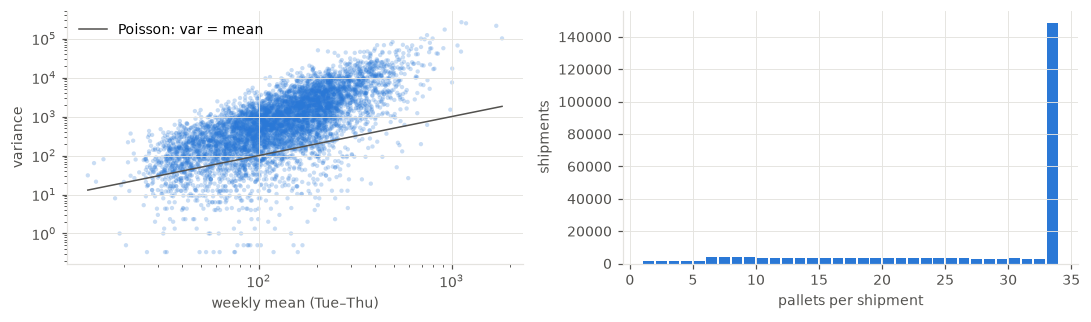

In [8]:
x = cust_day[cust_day.ship_date < CUTOFF].copy()
x["wk"] = x.ship_date.dt.to_period("W")
x["dow"] = x.ship_date.dt.dayofweek
m = x[x.dow.between(1, 3)].groupby(["customer_id", "wk"]).pallets.agg(["mean", "var"]).dropna()
m = m[m["mean"] > 5]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].scatter(m["mean"], m["var"], s=8, alpha=0.25, color=SERIES[0], edgecolors="none")
mm = np.linspace(m["mean"].min(), m["mean"].max(), 50)
axes[0].plot(mm, mm, color=INK2, lw=1, label="Poisson: var = mean")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].legend(frameon=False)
axes[0].set_xlabel("weekly mean (Tue–Thu)"); axes[0].set_ylabel("variance")
axes[1].hist(ship.pallets, bins=range(1, 35), color=SERIES[0], rwidth=0.85)
axes[1].set_xlabel("pallets per shipment"); axes[1].set_ylabel("shipments")
fig.tight_layout(); fig.savefig(FIG / "s1_dispersion.png")

Variance sits well above the Poisson line, so the data is overdispersed. (Caveat: each point is a 3-day variance, so individual points are noisy; the overall shift is what matters.) S3 should evaluate with scale-free metrics (MASE, WAPE) and consider a Tweedie or Poisson objective. About 60% of shipments are full 33-pallet trucks; the rest are partial loads, including each customer-day's remainder.

## 8. Data-quality summary (from the validation reports)

In [9]:
rep = {p.stem: json.loads(p.read_text()) for p in (ROOT / "reports" / "validation").glob("*.json")
       if p.stem != "summary"}
dq = pd.DataFrame([{"batch": k, "status": r["status"], "rows_in": r["rows_in"],
                    "quarantined": r["quarantined"], "dups_dropped": r["exact_duplicates_dropped"],
                    "corrections": r["superseded_by_correction"], **r["warnings_by_type"]}
                   for k, r in sorted(rep.items())]).fillna(0)
dq

,batch,status,rows_in,quarantined,dups_dropped,corrections,missing_operating_day,volume_low,volume_high
0,history,warn,193775,328,396,595,33.0,7.0,1.0
1,live-2026-01,pass,5901,16,12,16,0.0,0.0,0.0
2,live-2026-02,pass,5425,12,8,14,0.0,0.0,0.0
3,live-2026-03,pass,6348,10,12,16,0.0,0.0,0.0
4,live-2026-04,pass,6404,14,14,17,0.0,0.0,0.0
5,live-2026-05,warn,6206,10,8,16,0.0,1.0,0.0
6,live-2026-06,pass,6607,12,7,11,0.0,0.0,0.0
7,live-2026-07,pass,6797,17,14,22,0.0,0.0,0.0
8,live-2026-08,pass,6146,14,13,19,0.0,0.0,0.0
9,live-2026-09,pass,6810,16,14,17,0.0,0.0,0.0


## 9. Pipeline audit against ground truth (simulation only)
How much true volume does the validated dataset lose, and where?

In [10]:
T = ROOT / "data" / "sim_truth"
truth = pd.read_parquet(T / "daily_truth.parquet").groupby(["site_id", "date"]).pallets_true.sum()
val = site_day.set_index(["site_id", "ship_date"]).pallets
val.index.names = ["site_id", "date"]
cmp = pd.concat([truth, val], axis=1).fillna(0)
cmp.columns = ["truth", "validated"]
cmp["gap"] = cmp.truth - cmp.validated
man = json.loads((T / "fault_manifest.json").read_text())
print(f"true pallets: {cmp.truth.sum():,.0f} | validated: {cmp.validated.sum():,.0f} "
      f"| missing: {cmp.gap.sum():,.0f} ({cmp.gap.sum() / cmp.truth.sum():.3%})")
print(f"  full outages: {man['outage_lost_pallets']:,}  partial outages: {man['partial_outage_lost_pallets']:,}")
print(f"site-days with any gap: {(cmp.gap != 0).sum()} of {(cmp.truth > 0).sum()}")

true pallets: 6,688,168 | validated: 6,624,277 | missing: 63,891 (0.955%)
  full outages: 41,488  partial outages: 9,294
site-days with any gap: 488 of 4770


About 80% of the missing volume (≈1% of all pallets) comes from the planted full and partial outages, every one of which validation flagged by date. Most of the remainder is quarantined rows (≈450 shipments). Corrections that hadn't arrived by snapshot time account for a few more. **Open question for S2:** flagged outage days must be imputed or masked. They must not be treated as real zero-demand days, or every lag feature downstream is distorted.